# Huấn Luyện Và Đánh Giá Mô Hình Linear SVC

In [1]:
import re
import string
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.svm import LinearSVC

## 1. Định nghĩa Bộ Tiền Xử Lý (Text Preprocessor) và Pipeline

In [2]:
class TextPreprocessor(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.stopwords = set([
            "i", "me", "my", "myself", "we", "our", "ours", "ourselves", "you", "your", "yours",
            "he", "him", "his", "she", "her", "it", "its", "they", "them", "their", "am", "is", "are",
            "was", "were", "be", "been", "being", "have", "has", "had", "having", "do", "does", "did",
            "the", "a", "an", "and", "but", "if", "or", "because", "as", "until", "while", "of", "at",
            "by", "for", "with", "about", "against", "between", "into", "through", "during", "before",
            "after", "above", "below", "to", "from", "up", "down", "in", "out", "on", "off", "over",
            "under", "again", "further", "then", "once"
        ])

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        cleaned_X = []
        for text in X:
            if not isinstance(text, str):
                text = str(text)

            text = text.lower()
            text = text.translate(str.maketrans('', '', string.punctuation))
            text = re.sub(r'\s+', ' ', text).strip()

            words = text.split()
            words = [word for word in words if word not in self.stopwords]

            cleaned_X.append(" ".join(words))

        return cleaned_X

def create_bec_pipeline(model_classifier):
    pipeline = Pipeline([
        ('preprocessor', TextPreprocessor()),
        ('tfidf', TfidfVectorizer()),
        ('classifier', model_classifier)
    ])
    return pipeline

## 2. Tải và Tiền Xử Lý Dữ Liệu

In [3]:
# Load datasets
clean_df = pd.read_csv("synthetic_emails.csv")
poisoned_df = pd.read_csv("synthetic_emails_poisoned.csv")

clean_df["subject"] = clean_df["subject"].fillna("")
clean_df["body"] = clean_df["body"].fillna("")
clean_df["text"] = clean_df["subject"] + " " + clean_df["body"]

poisoned_df["subject"] = poisoned_df["subject"].fillna("")
poisoned_df["body"] = poisoned_df["body"].fillna("")
poisoned_df["text"] = poisoned_df["subject"] + " " + poisoned_df["body"]

# Chỉ lấy các dòng email thực sự bị tấn công (để tránh trùng lặp dữ liệu)
modified_indices = []
for i in range(len(clean_df)):
    if clean_df.loc[i, "body"] != poisoned_df.loc[i, "body"]:
        modified_indices.append(i)

clean_filtered = clean_df.loc[modified_indices].copy()
poisoned_filtered = poisoned_df.loc[modified_indices].copy()

clean_filtered["target"] = 0
poisoned_filtered["target"] = 1

# Gộp tập dữ liệu đã lọc sạch trùng lặp
df = pd.concat([clean_filtered, poisoned_filtered], ignore_index=True)

print("Tổng số mẫu dữ liệu sạch:", len(clean_filtered))
print("Tổng số mẫu dữ liệu bị tấn công:", len(poisoned_filtered))
print("Tổng kích thước tập dữ liệu:", df.shape)

Tổng số mẫu dữ liệu sạch: 1187
Tổng số mẫu dữ liệu bị tấn công: 1187
Tổng kích thước tập dữ liệu: (2374, 5)


## 3. Chia Tập Dữ Liệu Train/Test

In [4]:
X = df["text"]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Kích thước tập Train:", X_train.shape[0])
print("Kích thước tập Test:", X_test.shape[0])

Kích thước tập Train: 1899
Kích thước tập Test: 475


## 4. Huấn Luyện Mô Hình Linear SVC

In [5]:
# Khởi tạo mô hình
svm_model = LinearSVC(random_state=42)

# Tạo pipeline
svm_pipeline = create_bec_pipeline(svm_model)

# Huấn luyện mô hình
print("Đang huấn luyện Linear SVC...")
svm_pipeline.fit(X_train, y_train)
print("Đã hoàn thành huấn luyện!")

Đang huấn luyện Linear SVC...
Đã hoàn thành huấn luyện!


## 5. Đánh Giá Hiệu Năng Mô Hình

===== Kết quả đánh giá Linear SVC =====
Accuracy:  0.7832
Precision: 0.8045
Recall:    0.7468
F1-score:  0.7746

Classification Report:
              precision    recall  f1-score   support

       Clean       0.76      0.82      0.79       238
    Poisoned       0.80      0.75      0.77       237

    accuracy                           0.78       475
   macro avg       0.78      0.78      0.78       475
weighted avg       0.78      0.78      0.78       475



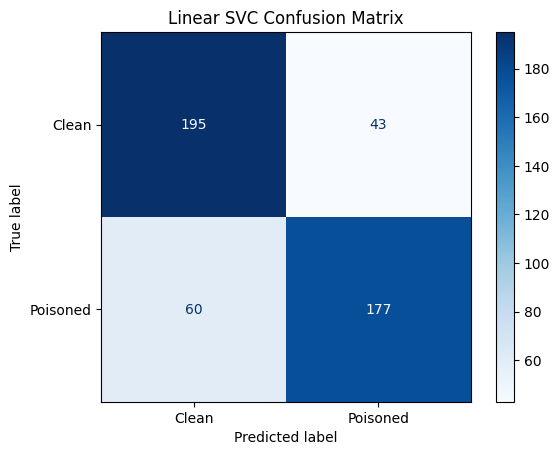

In [6]:
# Dự đoán trên tập kiểm thử
y_pred = svm_pipeline.predict(X_test)

# Tính toán các chỉ số đánh giá
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("===== Kết quả đánh giá Linear SVC =====") 
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Clean", "Poisoned"]))

# Vẽ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Clean", "Poisoned"])
disp.plot(cmap=plt.cm.Blues)
plt.title("Linear SVC Confusion Matrix")
plt.show()